# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: The Pre-Publish Ethics Review

### Scenario

You're a junior analyst at **Northwind Retail Insights**. A colleague drafted a set of
charts for tomorrow's regional performance report, and your manager asked you to review
them before they go out. She's blunt about what she wants checked:

1. *"I can't tell what I'm supposed to look at first on any of these charts. There's no
   hierarchy."*
2. *"One of these charts will get someone using a grayscale office printer completely
   lost. Fix that before it ships."*
3. *"I saw a headline chart that made a tiny year-over-year change look like a crisis.
   Check the axis."*
4. *"Someone wrote 'this PROVES our new strategy is working' under a chart. That's not
   what a data label is for."*

You'll work through the same review a real analyst would: fix a hierarchy problem, make
a chart accessible, catch a scale exaggeration, and rewrite an overreaching annotation.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real sales data you'll be working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

sales = pd.read_csv("superstore.csv", encoding="latin-1")
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Year"] = sales["Order Date"].dt.year

print(f"Loaded {len(sales):,} orders, {sales.Year.min()}-{sales.Year.max()}.")
sales[["Order Date", "Region", "Product Category", "Sales", "Profit"]].head()

Loaded 8,399 orders, 2009-2012.


,Order Date,Region,Product Category,Sales,Profit
0,2010-10-13,Nunavut,Office Supplies,261.5400,-213.25
1,2012-10-01,Nunavut,Office Supplies,10123.0200,457.81
2,2012-10-01,Nunavut,Office Supplies,244.5700,46.71
3,2011-07-10,Nunavut,Technology,4965.7595,1198.97
4,2010-08-28,Nunavut,Office Supplies,394.2700,30.94


## Task 1 — Fix the Missing Hierarchy (Complaint #1)

**Real-world usage:** The manager can't tell what to look at first on the current
chart.

**Why this technique:** Visual hierarchy (size + weight + color) creates an
unmistakable primary -> secondary -> tertiary reading order without needing
instructions.

**TODO:** Build a figure with 3 text elements, using ONLY `fontsize`, `fontweight`, and
`color` to create hierarchy:
1. **Primary:** the region with the highest total profit, in large bold colored text.
2. **Secondary:** one supporting sentence, medium size, muted color.
3. **Tertiary:** a data-source footnote, small, light gray.

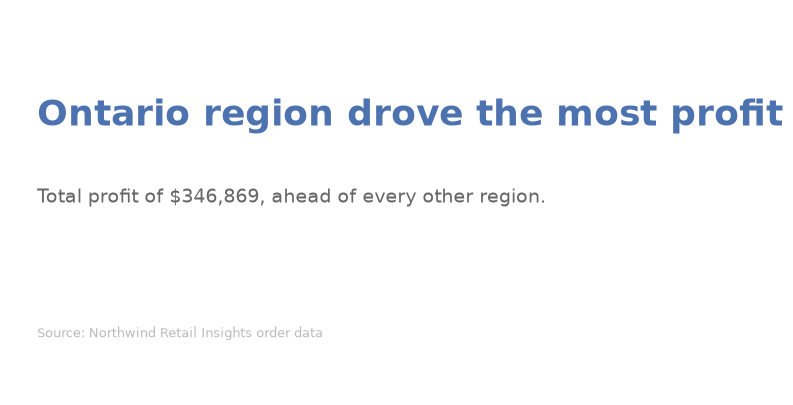

In [2]:

region_totals = sales.groupby("Region")["Profit"].sum().sort_values()
best_region = region_totals.idxmax()

fig, ax = plt.subplots(figsize=(7, 5))
ax.axis("off")

# TODO 1: primary element -- large, bold, colored
ax.text(0.05, 0.7, f"{best_region} region drove the most profit", fontsize=26,
        fontweight="bold", color="#4C72B0", transform=ax.transAxes)

# TODO 2: secondary element -- medium, muted color
ax.text(0.05, 0.5, f"Total profit of ${region_totals.max():,.0f}, ahead of every other region.",
        fontsize=14, color="#666666", transform=ax.transAxes)

# TODO 3: tertiary element -- small, light gray
ax.text(0.05, 0.15, "Source: Northwind Retail Insights order data",
        fontsize=9, color="#bbbbbb", transform=ax.transAxes)

plt.show()


**Reflection:** Without reading any labels, in what order do your eyes land on the
three text elements? If someone glanced at this for only 2 seconds, what's the one
fact they'd walk away with?

_Your answer:_

My eyes land on the large bold blue heading first, then move down to the muted supporting sentence, and only notice the small light gray footnote last, if at all. In a two second glance, the one fact I would walk away with is which region drove the most profit, since that is the only piece of text large and bold enough to register immediately.

## Task 2 — Make the Chart Accessible (Complaint #2)

**Real-world usage:** A colorblind or grayscale-printer viewer needs to be able to read
this chart too.

**Why this technique:** Redundant coding (color + pattern/shape) survives both
colorblindness and grayscale printing; color alone does not.

**TODO:**
1. Build a bar chart of total `Sales` by `Product Category`, one color per category.
2. Add a DIFFERENT hatch pattern per bar (`hatch="//"`, `"xx"`, `".."`) on top of the
   color, so the categories stay distinguishable if color is stripped away.
3. Add a legend showing category name.

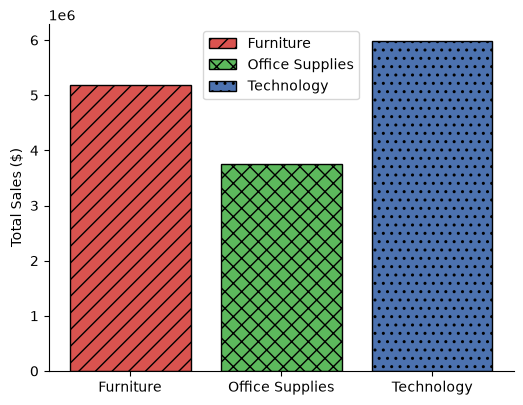

In [3]:

cat_sales = sales.groupby("Product Category")["Sales"].sum()

# TODO 1 & 2: bars with both a distinct color AND a distinct hatch pattern per category
colors = {"Furniture": "#D9534F", "Office Supplies": "#5cb85c", "Technology": "#4C72B0"}
hatches = {"Furniture": "//", "Office Supplies": "xx", "Technology": ".."}

fig, ax = plt.subplots(figsize=(6, 4.5))
for cat in cat_sales.index:
    ax.bar(cat, cat_sales[cat], color=colors[cat], hatch=hatches[cat], edgecolor="black", label=cat)

# TODO 3: legend
ax.legend()
ax.set_ylabel("Total Sales ($)")
plt.show()


**Reflection:** If you only used color (no hatch pattern), which two accessibility
failure modes from the lecture would this chart hit? Name both.

_Your answer:_

Without the hatch patterns, this chart would fail in two ways. First, someone with red green color blindness could easily confuse the red and green bars, since those hues are a classic pair that is hard to tell apart under that condition. Second, if the chart were printed or photocopied in grayscale, all three colors would collapse into similar shades of gray and the categories would become indistinguishable from one another.

## Task 3 — Catch the Axis Exaggeration (Complaint #3)

**Real-world usage:** A headline chart made a small real change look like a crisis.

**Why this technique:** Comparing the SAME data on a zero-baseline axis vs. a truncated
axis reveals exactly how much an axis choice is doing the "storytelling" instead of the
data.

**TODO:**
1. Compute total `Sales` by `Year`.
2. Compute the real percent change between the two most recent years.
3. Plot BOTH a zero-baseline version and a truncated-axis version, side by side, each
   titled with the real percent change.

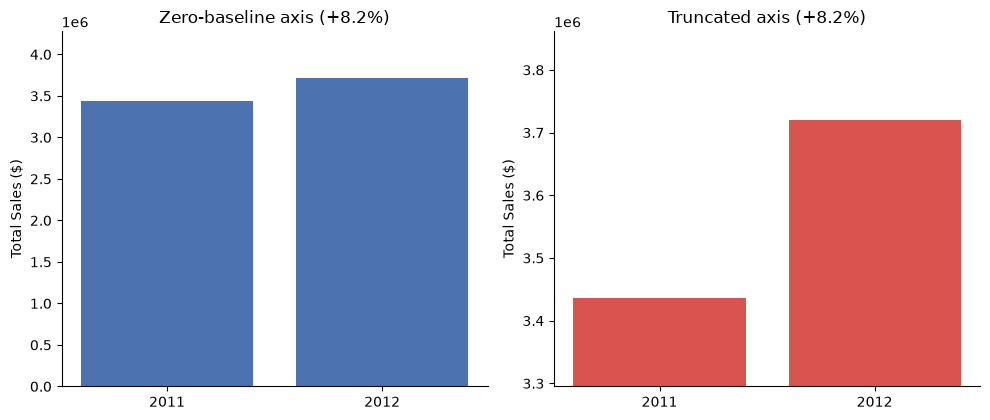

Real change from 2011 to 2012: +8.2%


In [4]:

yearly_sales = sales.groupby("Year")["Sales"].sum()

# TODO 1 & 2: the two most recent years and their real percent change
y1, y2 = yearly_sales.index[-2], yearly_sales.index[-1]
v1, v2 = yearly_sales[y1], yearly_sales[y2]
pct_change = (v2 - v1) / v1 * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))

# TODO 3a: zero-baseline version (axes[0])
axes[0].bar([str(y1), str(y2)], [v1, v2], color="#4C72B0")
axes[0].set_ylim(0, max(v1, v2) * 1.15)
axes[0].set_title(f"Zero-baseline axis ({pct_change:+.1f}%)")
axes[0].set_ylabel("Total Sales ($)")

# TODO 3b: truncated-axis version (axes[1]) -- pick tight y-limits close to v1/v2
axes[1].bar([str(y1), str(y2)], [v1, v2], color="#D9534F")
margin = abs(v2 - v1) * 0.5
axes[1].set_ylim(min(v1, v2) - margin, max(v1, v2) + margin)
axes[1].set_title(f"Truncated axis ({pct_change:+.1f}%)")
axes[1].set_ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

print(f"Real change from {y1} to {y2}: {pct_change:+.1f}%" if pct_change is not None else "Fill in pct_change above")


**Reflection:** Which of your two panels would you flag for the manager as
potentially misleading if it were used ALONE as the report's headline chart, with no
other context? Why?

_Your answer:_

I would flag the truncated axis panel as the misleading one. Even though both panels show the exact same percent change in their titles, cropping the y axis so it starts near the data values instead of at zero makes the bars look wildly different in height, which visually exaggerates a change that is actually fairly small. Shown alone with no caption explaining the axis choice, a reader would likely walk away thinking something dramatic happened when it did not.

## Task 4 — Rewrite the Overreaching Annotation (Complaint #4)

**Real-world usage:** A colleague's annotation claimed a chart "PROVES" a strategy is
working — language the data alone cannot support.

**Why this technique:** Distinguishing descriptive / interpretive / persuasive
annotation lets you keep useful interpretation while cutting unsupported claims.

**TODO:**
1. Given the overreaching annotation text below, write a DESCRIPTIVE version (states
   only the fact) and an INTERPRETIVE version (explains a plausible, appropriately
   hedged reason) — no causal "PROVES" language in either.
2. Plot the yearly sales trend with your INTERPRETIVE annotation on the most recent
   data point.

ORIGINAL (persuasive, overreaching): This PROVES our new strategy is working -- scale it up immediately
DESCRIPTIVE: Sales rose from $3,436,817 to $3,719,964 between 2011 and 2012.
INTERPRETIVE: Sales increased this year, which may partly reflect the new strategy alongside other seasonal and market factors.


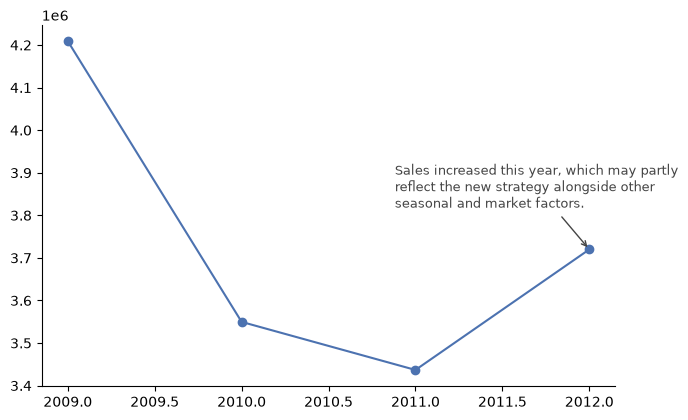

In [5]:

overreaching_original = "This PROVES our new strategy is working -- scale it up immediately"

# TODO 1: your rewrites
descriptive_version = (
    f"Sales rose from ${yearly_sales.iloc[-2]:,.0f} to ${yearly_sales.iloc[-1]:,.0f} "
    f"between {yearly_sales.index[-2]} and {yearly_sales.index[-1]}."
)
interpretive_version = (
    "Sales increased this year, which may partly reflect the new strategy alongside "
    "other seasonal and market factors."
)

print("ORIGINAL (persuasive, overreaching):", overreaching_original)
print("DESCRIPTIVE:", descriptive_version)
print("INTERPRETIVE:", interpretive_version)

# TODO 2: plot with your interpretive annotation on the last data point
fig, ax = plt.subplots(figsize=(7, 4.3))
ax.plot(yearly_sales.index, yearly_sales.values, "o-", color="#4C72B0")
# TODO: ax.annotate(...) using interpretive_version, pointing at the last year's value
ax.annotate(
    interpretive_version,
    xy=(yearly_sales.index[-1], yearly_sales.values[-1]),
    xytext=(-140, 30),
    textcoords="offset points",
    fontsize=9,
    color="#444444",
    wrap=True,
    arrowprops=dict(arrowstyle="->", color="#444444"),
)

plt.tight_layout()
plt.show()


**Reflection:** What specific evidence would you need (that this dataset alone
doesn't provide) before the ORIGINAL "proves it's working" claim would actually be
justified?

_Your answer:_

To justify a claim that the new strategy actually caused the sales increase, I would need more than a single before and after comparison. That would mean having a control group, such as similar regions or stores that did not receive the new strategy, so the change could be compared against a baseline with no intervention. I would also want to rule out seasonal patterns, marketing spend, pricing changes, and broader market trends from the same period, ideally through a proper A/B test or at least a longer historical trend showing this jump is unusual rather than part of normal year to year variation.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence sign-off note to your manager summarizing
this review. Your answer should:
- State which ONE of the four fixes above you consider the most urgent to ship before
  tomorrow, and why.
- Reference the lecture's 5-question Ethical Visualization Audit — pick one question
  from it and explain how it applies to Task 3 or Task 4 specifically.
- Name one guardrail (a review step, a style-guide rule, etc.) you'd recommend
  permanently adding to the team's process to prevent these four issues recurring.

_Your final recommendation here:_

Of the four issues we reviewed, I think the axis exaggeration in Task 3 is the most urgent to fix before tomorrow, because a misleading headline chart can shape the entire narrative of the report before anyone reads a single word of text. One question from the Ethical Visualization Audit is whether the axis starts at zero or, if it does not, whether that choice is clearly disclosed to the reader, and that question applies directly to Task 3, where the truncated axis panel makes a modest change look far larger than it really is with no note explaining the scale. The same audit lens matters for Task 4 too, since an annotation claiming a chart PROVES something is really answering the audit question of whether the wording matches what the data can actually support, and here it clearly does not. Going forward, I would recommend adding a mandatory second reviewer sign off step before any chart ships, where that reviewer's only job is to check the axis choice and the wording of every annotation against the underlying numbers. That single guardrail would have caught both the axis and the annotation problems before they ever reached the manager's desk.